# Praktikum Data Mining — Association Rule Mining: Pengerjaan Tugas 1–4
**Program Studi Informatika — Universitas Negeri Padang**

Notebook ini berisi pengerjaan Tugas 1–4. Langkah-langkah praktikum (Bagian 4.1–4.8) ada di `Praktikum_ARM_1_Langkah.ipynb`.

Berkas data yang dibutuhkan (letakkan di folder yang sama dengan notebook):
`transactions_arm_praktikum.csv`, `transactions_arm_praktikum_onehot.csv` (Tugas 1–3), dan `TRANSAKSI_TOKO_BANGUNAN_GABUNGAN.csv` (Tugas 4).

> Isi nama dan NIM Anda pada sel berikut sebelum membuat laporan.

In [1]:
NAMA = "Nama Mahasiswa"
NIM  = "NIM"
KELAS = "Kelas"

### Persiapan: data dasar, Apriori, dan aturan asosiasi
Sel-sel berikut mengulang hasil Bagian 4 (Dataset 1, `min_support = 0.15`, `min_confidence = 0.5`) yang dibutuhkan oleh Tugas 1–4.

In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

os.makedirs('figs', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
NAVY = '#1E2761'

# Dataset 1 -> one-hot
raw = pd.read_csv('transactions_arm_praktikum.csv')
transactions = [[i.strip() for i in s.split(',')] for s in raw['Items']]
te = TransactionEncoder()
df = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

# Apriori dan aturan asosiasi (sama seperti Bagian 4.3 dan 4.4)
MIN_SUP, MIN_CONF = 0.15, 0.5
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True).sort_values('support', ascending=False)
rules = association_rules(freq_apriori, num_itemsets=len(df), metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)
def fmt(s): return ', '.join(sorted(s))
rules['aturan'] = rules['antecedents'].apply(fmt) + ' → ' + rules['consequents'].apply(fmt)

def cari(ant, con):
    return rules[(rules['antecedents'] == frozenset(ant)) & (rules['consequents'] == frozenset(con))].iloc[0]

# fungsi pembanding waktu Apriori vs FP-Growth
def bandingkan(data, sup, ulang=30):
    # waktu = rata-rata dari beberapa kali pengulangan agar lebih stabil
    ta, tf = [], []
    for _ in range(ulang):
        t0 = time.perf_counter(); fa = apriori(data, min_support=sup, use_colnames=True); ta.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); ff = fpgrowth(data, min_support=sup, use_colnames=True); tf.append(time.perf_counter() - t0)
    same = set(map(frozenset, fa['itemsets'])) == set(map(frozenset, ff['itemsets']))
    return len(fa), len(ff), np.mean(ta)*1000, np.mean(tf)*1000, same

print('Siap:', len(df), 'transaksi,', len(freq_apriori), 'itemset,', len(rules), 'aturan')

Siap: 60 transaksi, 17 itemset, 18 aturan


# Tugas 1 — Eksplorasi Ambang Batas min_support dan min_confidence

### 1.1 min_support = 0.10 vs 0.15 (min_confidence = 0.5)

In [3]:
fi_010 = apriori(df, min_support=0.10, use_colnames=True)
r_010 = association_rules(fi_010, num_itemsets=len(df), metric='confidence', min_threshold=0.5)
r_010 = r_010.sort_values('lift', ascending=False).reset_index(drop=True)
r_010['aturan'] = r_010['antecedents'].apply(fmt) + ' → ' + r_010['consequents'].apply(fmt)

print(pd.DataFrame({'min_support': [0.10, 0.15],
                    'itemset': [len(fi_010), len(freq_apriori)],
                    'aturan': [len(r_010), len(rules)]}).to_string(index=False))

baru = set(r_010['aturan']) - set(rules['aturan'])
print('\nAturan yang muncul hanya pada min_support = 0.10:')
print(r_010[r_010['aturan'].isin(baru)][['aturan','support','confidence','lift']].round(3).to_string(index=False))
print('\nItemset tambahan pada min_support = 0.10:')
tambahan = set(map(frozenset, fi_010['itemsets'])) - set(map(frozenset, freq_apriori['itemsets']))
for t in tambahan: print(' ', sorted(t), 'support =', round(float(fi_010[fi_010['itemsets']==t]['support'].iloc[0]), 3))

 min_support  itemset  aturan
        0.10       19      20
        0.15       17      18

Aturan yang muncul hanya pada min_support = 0.10:
     aturan  support  confidence  lift
Kopi → Gula    0.133       0.615 2.637
Gula → Kopi    0.133       0.571 2.637

Itemset tambahan pada min_support = 0.10:
  ['Gula', 'Kopi'] support = 0.133
  ['Keju'] support = 0.1


**Analisis 1.1.** Menurunkan `min_support` dari 0.15 ke 0.10 menambah 2 itemset (19 vs 17) dan 2 aturan (20 vs 18). Itemset tambahannya adalah `{Keju}` (tunggal, tidak membentuk aturan) dan `{Gula, Kopi}` (support 0.133, hanya 8 transaksi) yang menghasilkan aturan `Gula → Kopi` dan `Kopi → Gula` (lift 2.637). Aturan baru ini didukung oleh jumlah transaksi yang lebih sedikit sehingga lebih rentan terhadap kebetulan.

### 1.2 min_confidence dinaikkan menjadi 0.7 (min_support = 0.15)

In [4]:
r_07 = rules[rules['confidence'] >= 0.7]
gugur = rules[rules['confidence'] < 0.7]
print(f'Aturan awal: {len(rules)} | lolos conf >= 0.7: {len(r_07)} | gugur: {len(gugur)}')
print('\nAturan yang LOLOS:')
print(r_07[['aturan','support','confidence','lift']].round(3).to_string(index=False))
print('\nAturan yang GUGUR:')
print(gugur[['aturan','support','confidence','lift']].round(3).to_string(index=False))

Aturan awal: 18 | lolos conf >= 0.7: 7 | gugur: 11

Aturan yang LOLOS:
              aturan  support  confidence  lift
Mentega, Susu → Roti    0.183       1.000 3.333
Roti, Susu → Mentega    0.183       0.846 2.986
Mentega, Roti → Susu    0.183       0.846 2.672
      Mentega → Roti    0.217       0.765 2.549
      Roti → Mentega    0.217       0.722 2.549
  Kecap → Mie Instan    0.150       0.750 2.500
         Roti → Susu    0.217       0.722 2.281

Aturan yang GUGUR:
              aturan  support  confidence  lift
Roti → Mentega, Susu    0.183       0.611 3.333
Mentega → Roti, Susu    0.183       0.647 2.986
      Sabun → Shampo    0.150       0.600 2.769
      Shampo → Sabun    0.150       0.692 2.769
Susu → Mentega, Roti    0.183       0.579 2.672
  Mie Instan → Kecap    0.150       0.500 2.500
         Susu → Roti    0.217       0.684 2.281
  Mie Instan → Telur    0.167       0.556 2.222
  Telur → Mie Instan    0.167       0.667 2.222
      Mentega → Susu    0.183       0.647 2.0

**Analisis 1.2.** Dengan `min_confidence = 0.7`, 7 dari 18 aturan masih lolos dan 11 gugur. Aturan yang gugur antara lain `Sabun → Shampo` (0.600), `Shampo → Sabun` (0.692), `Mie Instan → Telur` (0.556), `Telur → Mie Instan` (0.667), `Mie Instan → Kecap` (0.500), `Susu → Roti` (0.684), dan `Susu → Mentega` / `Mentega → Susu`. Perhatikan bahwa aturan berlift tinggi seperti `Sabun → Shampo` (2.769) ikut gugur karena confidence-nya di bawah 0.7.

### 1.3 Sweep min_confidence (min_support = 0.15)

In [5]:
sweep_conf = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
res_conf = []
for c in sweep_conf:
    r = association_rules(freq_apriori, num_itemsets=len(df), metric='confidence', min_threshold=c)
    res_conf.append((c, len(r)))
    print(f'min_confidence={c:.1f}: {len(r):2d} aturan')

min_confidence=0.5: 18 aturan
min_confidence=0.6: 14 aturan
min_confidence=0.7:  7 aturan
min_confidence=0.8:  3 aturan
min_confidence=0.9:  1 aturan
min_confidence=1.0:  1 aturan


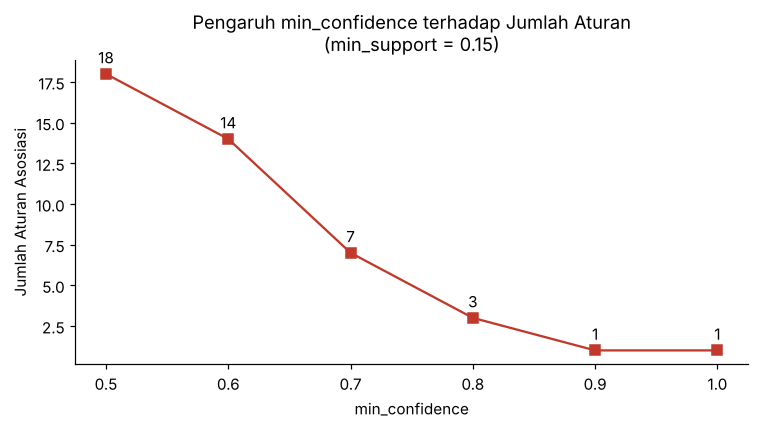

In [6]:
x, y = zip(*res_conf)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, y, 's-', color='#C0392B')
for xi, yi in zip(x, y): ax.annotate(str(yi), (xi, yi), textcoords='offset points', xytext=(0, 7), ha='center')
ax.set_xlabel('min_confidence'); ax.set_ylabel('Jumlah Aturan Asosiasi')
ax.set_title('Pengaruh min_confidence terhadap Jumlah Aturan\n(min_support = 0.15)')
plt.tight_layout(); plt.savefig('figs/tugas1_sweep_confidence.png'); plt.show()

**Analisis 1.3 dan 1.4 (trade-off).** Jumlah aturan turun monoton: 18 (0.5), 14 (0.6), 7 (0.7), 3 (0.8), 1 (0.9), 1 (1.0). Satu-satunya aturan yang bertahan sampai confidence 1.0 adalah `Mentega, Susu → Roti`.

* **Ambang rendah** (`min_support` 0.10 atau `min_confidence` 0.5): lebih banyak aturan dan lebih banyak peluang pola baru, tetapi aturan yang muncul bisa didukung hanya 8 transaksi (mis. `Gula ↔ Kopi`) dan ikut membawa aturan berconfidence sedang yang belum tentu dapat ditindaklanjuti.
* **Ambang tinggi**: aturan yang tersisa lebih andal, tetapi pola bermakna ikut hilang (mis. `Sabun ↔ Shampo` gugur pada confidence 0.7, padahal lift-nya 2.769).
* Karena itu ambang perlu dipilih bersama Lift dan jumlah transaksi pendukung, bukan hanya confidence. Pasangan `min_support = 0.15` dan `min_confidence = 0.5` memberi keseimbangan: 18 aturan, seluruhnya Lift > 2.

# Tugas 2 — Analisis Mendalam Aturan yang Belum Dibahas

Dipilih dua aturan yang belum dibahas pada Bagian 4.6:
1. **Mie Instan → Telur**  (kelompok mie instan)
2. **Susu → Roti**  (bagian dari kelompok sarapan, tanpa Mentega)

Rumus: `leverage(X→Y) = support(X∪Y) − support(X)·support(Y)` dan
`conviction(X→Y) = (1 − support(Y)) / (1 − confidence(X→Y))`.

In [7]:
N = len(df)
def hitung(ant, con):
    sup = lambda cols: df[list(cols)].all(axis=1).mean()
    s_xy, s_x, s_y = sup(ant + con), sup(ant), sup(con)
    conf = s_xy / s_x
    lift = conf / s_y
    lev = s_xy - s_x * s_y
    conv = (1 - s_y) / (1 - conf) if conf < 1 else float('inf')
    return dict(aturan=f"{', '.join(ant)} → {', '.join(con)}", support_X=s_x, support_Y=s_y,
                support=s_xy, confidence=conf, lift=lift, leverage=lev, conviction=conv)

pilihan = [(['Mie Instan'], ['Telur']), (['Susu'], ['Roti'])]
t2 = pd.DataFrame([hitung(a, c) for a, c in pilihan])
print(t2.round(4).to_string(index=False))

            aturan  support_X  support_Y  support  confidence   lift  leverage  conviction
Mie Instan → Telur     0.3000       0.25   0.1667      0.5556 2.2222    0.0917      1.6875
       Susu → Roti     0.3167       0.30   0.2167      0.6842 2.2807    0.1217      2.2167


In [8]:
# Verifikasi terhadap keluaran mlxtend
for a, c in pilihan:
    r = cari(a, c)
    print(f"{fmt(r['antecedents'])} → {fmt(r['consequents'])}: leverage={r['leverage']:.4f}, conviction={r['conviction']:.4f}, lift={r['lift']:.4f}")

Mie Instan → Telur: leverage=0.0917, conviction=1.6875, lift=2.2222
Susu → Roti: leverage=0.1217, conviction=2.2167, lift=2.2807


**Perbandingan dengan Lift.**

| Aturan | Support | Confidence | Lift | Leverage | Conviction |
|---|---|---|---|---|---|
| Mie Instan → Telur | 0.167 | 0.556 | 2.222 | 0.092 | 1.688 |
| Susu → Roti | 0.217 | 0.684 | 2.281 | 0.122 | 2.217 |

Lift kedua aturan hampir sama (2.22 vs 2.28), tetapi leverage dan conviction membedakannya. `Susu → Roti` memiliki leverage 0.122 (sekitar 7 transaksi lebih banyak dari yang diharapkan bila independen, dari 60) dibanding `Mie Instan → Telur` 0.092 (sekitar 5,5 transaksi). Conviction `Susu → Roti` (2.22) juga lebih tinggi daripada `Mie Instan → Telur` (1.69): dugaan "Susu dibeli tanpa Roti" lebih jarang terjadi daripada yang diharapkan bila keduanya independen.

**Interpretasi bisnis.**
* **Mie Instan → Telur** (confidence 55,6%; Telur → Mie Instan 66,7%): tempatkan telur dekat rak mie instan atau tawarkan paket "Mie Instan + Telur". Pasangan ini juga terhubung dengan `Kecap → Mie Instan`, sehingga ketiganya dapat dijadikan paket "Menu Mie Praktis".
* **Susu → Roti** (confidence 68,4%): pembeli susu cenderung membeli roti. Letakkan roti di dekat susu atau tampilkan rekomendasi roti pada pembelian susu. Karena aturan ini berasal dari kelompok sarapan, tambahkan Mentega ke dalam paket untuk menaikkan nilai belanja (`Roti, Susu → Mentega` confidence 0.846).
* Aturan asosiasi menunjukkan korelasi, bukan sebab-akibat; promo sebaiknya diuji (mis. A/B testing).

# Tugas 3 — Apriori vs FP-Growth pada min_support = 0.05

In [9]:
hasil3 = []
for s in [0.15, 0.05]:
    n_a, n_f, t_a, t_f, same = bandingkan(df, s)
    hasil3.append(dict(min_support=s, itemset_apriori=n_a, itemset_fpgrowth=n_f,
                       waktu_apriori_ms=round(t_a, 2), waktu_fpgrowth_ms=round(t_f, 2),
                       selisih_ms=round(t_a - t_f, 2), rasio=round(t_a / t_f, 2), identik=same))
t3 = pd.DataFrame(hasil3)
print(t3.to_string(index=False))

 min_support  itemset_apriori  itemset_fpgrowth  waktu_apriori_ms  waktu_fpgrowth_ms  selisih_ms  rasio  identik
        0.15               17                17              1.90               1.20         0.7   1.58     True
        0.05               42                42              1.98               1.38         0.6   1.43     True


In [10]:
# Pada data sekecil ini, waktu Apriori/FP-Growth hanya hitungan milidetik. Untuk melihat tren skala,
# diuji juga pada beberapa ukuran data (transaksi direplikasi) dengan min_support = 0.05.
rows = []
for k in [1, 10, 100, 500]:
    big = pd.concat([df] * k, ignore_index=True)
    _, _, ta_, tf_, _ = bandingkan(big, 0.05, ulang=5)
    rows.append(dict(jumlah_transaksi=len(big), apriori_ms=round(ta_, 2), fpgrowth_ms=round(tf_, 2), rasio=round(ta_ / tf_, 2)))
skala = pd.DataFrame(rows); print(skala.to_string(index=False))

 jumlah_transaksi  apriori_ms  fpgrowth_ms  rasio
               60        2.07         1.28   1.62
              600        1.93         3.05   0.63
             6000        2.36        17.90   0.13
            30000        5.33        84.92   0.06


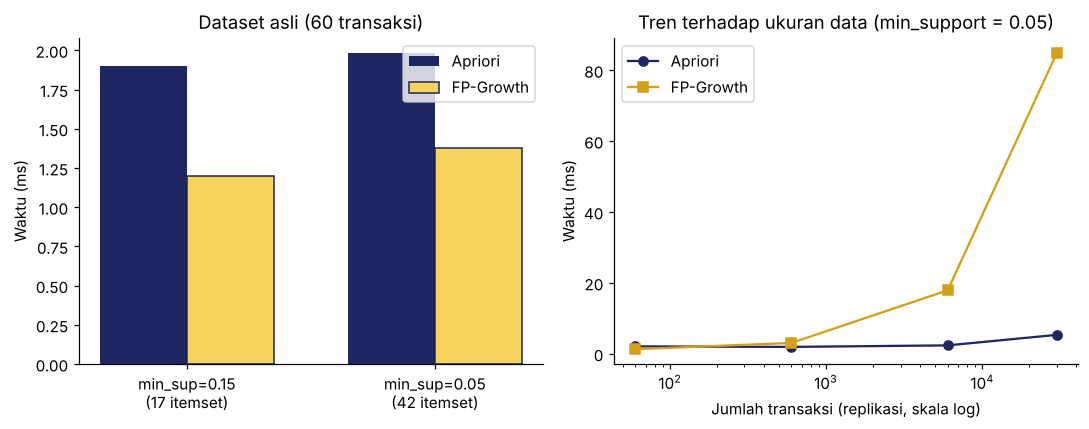

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
w = 0.35; xs = np.arange(2)
axs[0].bar(xs - w/2, t3['waktu_apriori_ms'], w, color=NAVY, label='Apriori')
axs[0].bar(xs + w/2, t3['waktu_fpgrowth_ms'], w, color='#F4D35E', edgecolor=NAVY, label='FP-Growth')
axs[0].set_xticks(xs); axs[0].set_xticklabels([f"min_sup={s}\n({n} itemset)" for s, n in zip(t3['min_support'], t3['itemset_apriori'])])
axs[0].set_ylabel('Waktu (ms)'); axs[0].set_title('Dataset asli (60 transaksi)'); axs[0].legend()
axs[1].plot(skala['jumlah_transaksi'], skala['apriori_ms'], 'o-', color=NAVY, label='Apriori')
axs[1].plot(skala['jumlah_transaksi'], skala['fpgrowth_ms'], 's-', color='#D4A017', label='FP-Growth')
axs[1].set_xscale('log'); axs[1].set_xlabel('Jumlah transaksi (replikasi, skala log)'); axs[1].set_ylabel('Waktu (ms)')
axs[1].set_title('Tren terhadap ukuran data (min_support = 0.05)'); axs[1].legend()
plt.tight_layout(); plt.savefig('figs/tugas3_perbandingan.png'); plt.show()

**Analisis Tugas 3.** Pada `min_support = 0.05`, jumlah itemset naik dari 17 menjadi 42 (identik pada kedua algoritma). Pada dataset asli FP-Growth sedikit lebih cepat pada kedua ambang (rasio sekitar 1,5× pada kedua ambang), tetapi selisihnya hanya sekitar 0,5–0,6 ms dan masih berada dalam rentang variasi pengukuran (angkanya sedikit berubah di setiap eksekusi). Jadi keunggulan FP-Growth **belum terlihat jelas** pada data sekecil ini; selisih besar seperti sekitar 3,5× pada modul tidak dapat direproduksi pada mesin dan versi pustaka yang dipakai di sini.

Uji tambahan dengan mereplikasi transaksi menunjukkan hasil yang berlawanan: pada 30.000 transaksi, Apriori mlxtend (sekitar 5 ms) lebih cepat daripada FP-Growth (sekitar 59 ms). Penyebabnya adalah implementasi, bukan teori. `apriori` pada mlxtend bekerja dengan operasi vektor NumPy pada matriks boolean sehingga hanya 12 kolom yang perlu dihitung, sedangkan `fpgrowth` membangun FP-Tree dengan kode Python murni yang biayanya naik seiring jumlah baris. Keunggulan teoretis FP-Growth (dua kali pemindaian dan tanpa pembangkitan kandidat) muncul ketika jumlah item sangat banyak dan kandidat Apriori meledak, kondisi yang tidak terpenuhi pada data dengan 12 item.

# Tugas 4 — Studi Kasus Mandiri: Toko Bangunan
Dataset mandiri disusun dari **Data Transaksi Toko Bangunan** (Kaggle, pengunggah *revgaming*):
https://www.kaggle.com/datasets/revgaming/data-transaksi-toko-bangunan

Berkas aslinya hanya berisi **30 transaksi**, sedangkan modul mensyaratkan minimal 40 transaksi dan 8 jenis item.
Karena itu dataset disusun ulang menjadi `TRANSAKSI_TOKO_BANGUNAN_GABUNGAN.csv` dengan komposisi:
* **30 transaksi asli** dari Kaggle (T001–T030), tidak diubah;
* **20 transaksi tambahan** (T031–T050) yang disusun sendiri dengan produk, kategori, satuan, dan harga satuan yang sama
  dengan data asli, mengikuti pola kebutuhan proyek umum (pondasi/dinding, pengecatan, instalasi pipa) ditambah 2 transaksi campuran acak.
  Kolom `Sumber` menandai asal tiap baris: `Kaggle (asli)` atau `Tambahan (disusun)`.

Format data adalah *long*: satu baris = satu produk pada satu transaksi. Untuk association rule mining hanya kolom
`ID Transaksi` dan `Produk` yang dipakai (ada/tidaknya produk, bukan jumlahnya).

In [12]:
# Dataset mandiri: Toko Bangunan (30 transaksi asli Kaggle + 20 transaksi tambahan), format long -> keranjang per transaksi
tb = pd.read_csv('TRANSAKSI_TOKO_BANGUNAN_GABUNGAN.csv')
print('Ukuran data mentah:', tb.shape)
print(tb[['ID Transaksi', 'Produk', 'Kategori', 'Kuantitas', 'Sumber']].iloc[[0, 1, 2, 90, 91, 92]].to_string(index=False))

print('\nTransaksi per sumber data:')
print(tb.groupby('Sumber')['ID Transaksi'].nunique().to_string())

# satu transaksi = himpunan produk unik pada ID Transaksi yang sama
toko = tb.groupby('ID Transaksi')['Produk'].apply(lambda s: sorted(set(s))).tolist()
ukuran = [len(t) for t in toko]
print('\nJumlah transaksi   :', len(toko), '(syarat modul >= 40)')
print('Jumlah jenis produk:', tb['Produk'].nunique(), '(syarat modul >= 8)')
print('Item per transaksi : min', min(ukuran), '| max', max(ukuran), '| rata-rata', round(sum(ukuran) / len(ukuran), 2))

Ukuran data mentah: (143, 9)
ID Transaksi        Produk            Kategori  Kuantitas             Sumber
        T001         Semen Material Konstruksi          5      Kaggle (asli)
        T001         Pasir Material Konstruksi          5      Kaggle (asli)
        T001    Cat Tembok                 Cat          8      Kaggle (asli)
        T031      Pipa PVC Bahan Logam dan PVC          7 Tambahan (disusun)
        T031 Sambungan PVC Bahan Logam dan PVC          7 Tambahan (disusun)
        T032 Sambungan PVC Bahan Logam dan PVC          3 Tambahan (disusun)

Transaksi per sumber data:
Sumber
Kaggle (asli)         30
Tambahan (disusun)    20

Jumlah transaksi   : 50 (syarat modul >= 40)
Jumlah jenis produk: 9 (syarat modul >= 8)
Item per transaksi : min 2 | max 4 | rata-rata 2.86


In [13]:
te4 = TransactionEncoder()
d4 = pd.DataFrame(te4.fit(toko).transform(toko), columns=te4.columns_)
print('Ukuran matriks one-hot:', d4.shape)
print('\nFrekuensi dan support tiap produk:')
frek = d4.sum().sort_values(ascending=False)
for item, n in frek.items():
    print(f'{item:14s}: {n:2d} transaksi (support = {n/len(d4):.3f})')

Ukuran matriks one-hot: (50, 9)

Frekuensi dan support tiap produk:
Kuas          : 21 transaksi (support = 0.420)
Semen         : 20 transaksi (support = 0.400)
Batu Bata     : 18 transaksi (support = 0.360)
Pasir         : 18 transaksi (support = 0.360)
Cat Tembok    : 16 transaksi (support = 0.320)
Besi Beton    : 15 transaksi (support = 0.300)
Cat Kayu      : 12 transaksi (support = 0.240)
Pipa PVC      : 12 transaksi (support = 0.240)
Sambungan PVC : 11 transaksi (support = 0.220)


In [14]:
MS4, MC4 = 0.10, 0.6
fi4 = apriori(d4, min_support=MS4, use_colnames=True).sort_values('support', ascending=False)
r4 = association_rules(fi4, num_itemsets=len(d4), metric='confidence', min_threshold=MC4)
r4 = r4.sort_values('lift', ascending=False).reset_index(drop=True)
r4['aturan'] = r4['antecedents'].apply(fmt) + ' → ' + r4['consequents'].apply(fmt)
r4['transaksi'] = (r4['support'] * len(d4)).round().astype(int)
print(f'min_support={MS4}, min_confidence={MC4}: {len(fi4)} itemset, {len(r4)} aturan')
print(r4[['aturan', 'transaksi', 'support', 'confidence', 'lift', 'leverage']].round(3).to_string(index=False))

min_support=0.1, min_confidence=0.6: 22 itemset, 14 aturan
                     aturan  transaksi  support  confidence  lift  leverage
   Pasir, Semen → Batu Bata         10     0.20       0.833 2.315     0.114
   Batu Bata, Semen → Pasir         10     0.20       0.769 2.137     0.106
 Sambungan PVC → Besi Beton          7     0.14       0.636 2.121     0.074
   Batu Bata, Pasir → Semen         10     0.20       0.833 2.083     0.104
Cat Kayu, Cat Tembok → Kuas          5     0.10       0.833 1.984     0.050
Cat Kayu, Kuas → Cat Tembok          5     0.10       0.625 1.953     0.049
          Pasir → Batu Bata         12     0.24       0.667 1.852     0.110
          Batu Bata → Pasir         12     0.24       0.667 1.852     0.110
          Semen → Batu Bata         13     0.26       0.650 1.806     0.116
          Batu Bata → Semen         13     0.26       0.722 1.806     0.116
          Cat Tembok → Kuas         12     0.24       0.750 1.786     0.106
              Semen → Pasir  

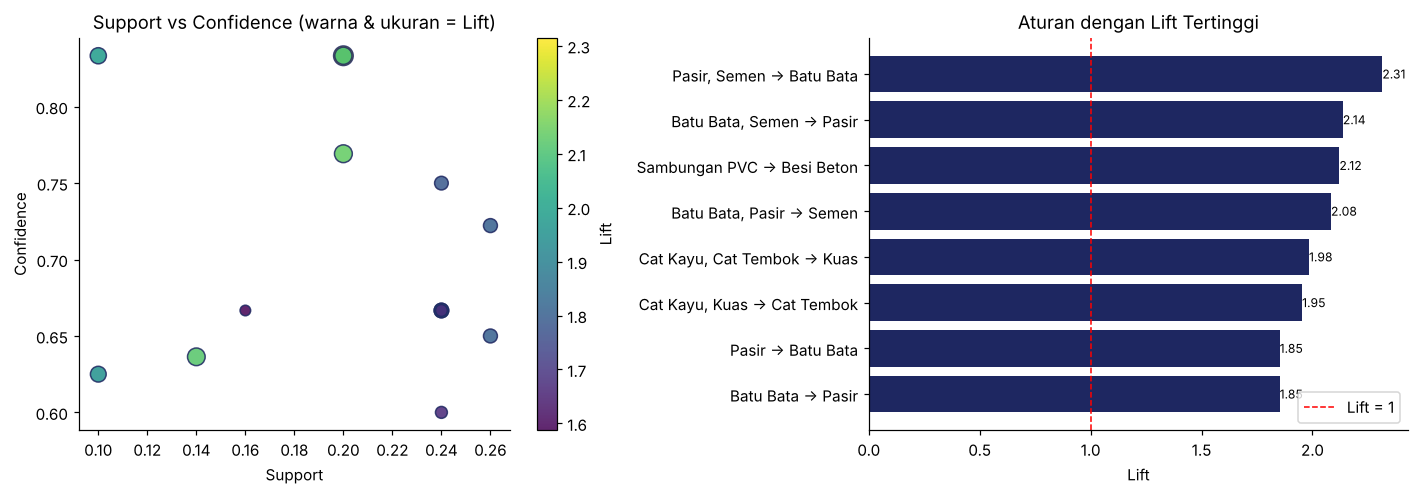

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
sz = (r4['lift'] - r4['lift'].min() + 0.3) * 160
sc = axs[0].scatter(r4['support'], r4['confidence'], s=sz, c=r4['lift'], cmap='viridis', alpha=0.85, edgecolor=NAVY)
plt.colorbar(sc, ax=axs[0], label='Lift')
axs[0].set_xlabel('Support'); axs[0].set_ylabel('Confidence'); axs[0].set_title('Support vs Confidence (warna & ukuran = Lift)')
t8 = r4.head(8).iloc[::-1]
b = axs[1].barh(t8['aturan'], t8['lift'], color=NAVY); axs[1].bar_label(b, fmt='%.2f', fontsize=8)
axs[1].axvline(1, color='red', ls='--', lw=1, label='Lift = 1'); axs[1].legend(loc='lower right')
axs[1].set_xlabel('Lift'); axs[1].set_title('Aturan dengan Lift Tertinggi')
plt.tight_layout(); plt.savefig('figs/tugas4_visualisasi.png'); plt.show()

In [16]:
# Sweep untuk memilih ambang batas
import math
for s in [0.05, 0.10, 0.15, 0.20, 0.25]:
    f = apriori(d4, min_support=s, use_colnames=True)
    hasil = []
    for c in (0.5, 0.6):
        r = association_rules(f, num_itemsets=len(d4), metric='confidence', min_threshold=c) if len(f) else []
        hasil.append(len(r))
    print(f'min_support={s:.2f} ({math.ceil(round(s * len(d4), 6))} transaksi): {len(f):2d} itemset | '
          f'aturan conf>=0.5: {hasil[0]:2d} | aturan conf>=0.6: {hasil[1]:2d}')

min_support=0.05 (3 transaksi): 37 itemset | aturan conf>=0.5: 27 | aturan conf>=0.6: 21
min_support=0.10 (5 transaksi): 22 itemset | aturan conf>=0.5: 19 | aturan conf>=0.6: 14
min_support=0.15 (8 transaksi): 15 itemset | aturan conf>=0.5: 15 | aturan conf>=0.6: 11
min_support=0.20 (10 transaksi): 14 itemset | aturan conf>=0.5: 14 | aturan conf>=0.6: 10
min_support=0.25 (13 transaksi):  7 itemset | aturan conf>=0.5:  2 | aturan conf>=0.6:  2


**Pemilihan ambang batas.** Dipilih `min_support = 0.10` (minimal 5 dari 50 transaksi) dan `min_confidence = 0.6`.
`min_support = 0.05` (3 transaksi) menghasilkan 37 itemset dan 21 aturan dengan banyak pola yang hanya muncul 3 kali; `0.15`–`0.20` menyisakan 10–11 aturan tetapi membuang pola yang masih bermakna
(mis. `Sambungan PVC → Besi Beton`, support 0.14) dan `0.25` hanya menyisakan 2 aturan. `min_confidence = 0.6` dipilih karena pada 0.5 terdapat 19 aturan dan 5 di antaranya berconfidence 0.50–0.59.

**Rekomendasi bisnis** (berdasarkan Lift tertinggi):
1. **Paket "Bahan Bangunan Dasar"** (`Pasir, Semen → Batu Bata`, lift 2.32, confidence 83,3%; `Batu Bata, Semen → Pasir`; `Batu Bata, Pasir → Semen`): bundling semen–pasir–batu bata.
2. **Paket "Instalasi Pipa dan Besi"** (`Sambungan PVC → Besi Beton`, lift 2.12, confidence 63,6%): tawarkan besi beton atau paket pipa-sambungan-besi kepada pembeli sambungan PVC.
3. **Paket "Pengecatan"** (`Cat Kayu, Cat Tembok → Kuas`, lift 1.98, confidence 83,3%; `Cat Tembok → Kuas`): letakkan kuas di dekat rak cat dan tawarkan paket cat + kuas.

Catatan: 20 dari 50 transaksi disusun sendiri (7 dari 10 transaksi pendukung `Pasir, Semen → Batu Bata` berasal dari data tambahan), sehingga hasil ini bersifat ilustrasi penerapan metode, bukan temuan perilaku pembeli yang sebenarnya.

## Ringkasan Seluruh Hasil

In [17]:
print('Aturan Lift tertinggi (Dataset 1):', rules.loc[0, 'aturan'], '| lift =', round(rules.loc[0, 'lift'], 3))
print('Aturan Lift tertinggi (Toko bangunan):', r4.loc[0, 'aturan'], '| lift =', round(r4.loc[0, 'lift'], 3))

Aturan Lift tertinggi (Dataset 1): Roti → Mentega, Susu | lift = 3.333
Aturan Lift tertinggi (Toko bangunan): Pasir, Semen → Batu Bata | lift = 2.315
